<a href="https://colab.research.google.com/github/kajalkalawat01-arch/week7-sales-analysis/blob/main/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cleaned Sales Data


,Date,Product,Quantity,Sales,Region
0,2026-01-05,Laptop,2,100000,North
1,2026-01-10,Mobile,5,75000,South
2,2026-02-03,Laptop,3,150000,East
3,2026-02-15,Tablet,4,80000,West
4,2026-03-08,Mobile,6,90000,North
5,2026-03-20,Laptop,2,110000,South
6,2026-04-04,Tablet,5,100000,East
7,2026-04-18,Mobile,3,45000,West
8,2026-05-10,Laptop,4,200000,North
9,2026-05-22,Tablet,6,120000,South


Total Sales: 1070000
Average Sales: 107000.0
Total Quantity Sold: 40

Product-wise Sales


,Sales
Product,
Laptop,560000
Mobile,210000
Tablet,300000


Top Selling Product: Laptop

Region-wise Sales


,Sales
Region,
East,250000
North,390000
South,305000
West,125000



Monthly Sales


,Sales
Date,
2026-01,175000
2026-02,230000
2026-03,200000
2026-04,145000
2026-05,320000


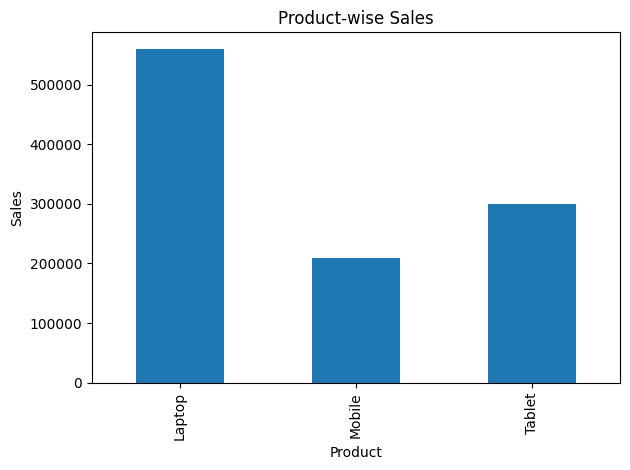

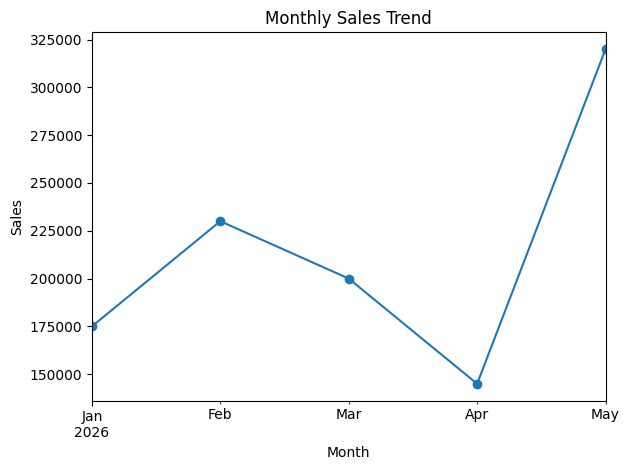

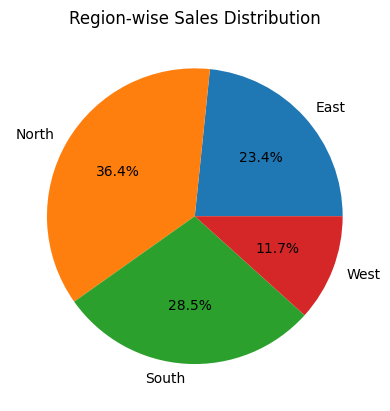


Sales Analysis Completed Successfully!
Report exported successfully!


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Create sales dataset
data = {
    "Date": [
        "2026-01-05", "2026-01-10", "2026-02-03",
        "2026-02-15", "2026-03-08", "2026-03-20",
        "2026-04-04", "2026-04-18", "2026-05-10",
        "2026-05-22"
    ],
    "Product": [
        "Laptop", "Mobile", "Laptop", "Tablet",
        "Mobile", "Laptop", "Tablet", "Mobile",
        "Laptop", "Tablet"
    ],
    "Quantity": [2, 5, 3, 4, 6, 2, 5, 3, 4, 6],
    "Sales": [100000, 75000, 150000, 80000, 90000,
              110000, 100000, 45000, 200000, 120000],
    "Region": [
        "North", "South", "East", "West", "North",
        "South", "East", "West", "North", "South"
    ]
}

df = pd.DataFrame(data)

# Convert Date column
df["Date"] = pd.to_datetime(df["Date"])

# Data cleaning
df = df.drop_duplicates()
df = df.dropna()

print("Cleaned Sales Data")
display(df)

# Total Sales
total_sales = df["Sales"].sum()
print("Total Sales:", total_sales)

# Average Sales
average_sales = df["Sales"].mean()
print("Average Sales:", average_sales)

# Total Quantity
print("Total Quantity Sold:", df["Quantity"].sum())

# Best Selling Product
product_sales = df.groupby("Product")["Sales"].sum()

print("\nProduct-wise Sales")
display(product_sales)

print("Top Selling Product:",
      product_sales.idxmax())

# Region-wise Sales
region_sales = df.groupby("Region")["Sales"].sum()

print("\nRegion-wise Sales")
display(region_sales)

# Monthly Sales Analysis
monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["Sales"].sum()

print("\nMonthly Sales")
display(monthly_sales)

# Bar Chart
product_sales.plot(kind="bar", title="Product-wise Sales")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

# Line Chart
monthly_sales.plot(
    kind="line", marker="o",
    title="Monthly Sales Trend"
)
plt.xlabel("Month")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

# Pie Chart
region_sales.plot(
    kind="pie", autopct="%1.1f%%",
    title="Region-wise Sales Distribution"
)
plt.ylabel("")
plt.show()

# Export report
df.to_csv("processed_sales_data.csv", index=False)

print("\nSales Analysis Completed Successfully!")
print("Report exported successfully!")